# Introduction to OVITO in Python

In this notebook we use the OVITO Python module (installed with `pip install ovito`) to load, analyze and render a multi-frame xyz file (`data/sample.xyz`).

Run the cells **in order from the top** with `Shift + Enter`.

## 0. Setup

The notebook runs inside the `notebooks/` folder, so the data path is `../data/sample.xyz`.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ovito
from ovito.io import import_file

print('OVITO version:', ovito.version_string)
XYZ = Path('../data/sample.xyz')
print('Data file found:', XYZ.is_file())

OVITO version: 3.17.0
Data file found: True


## 1. Load the file

`import_file` creates a **pipeline**. A pipeline is the flow "input data → modifiers → result", the same idea as the panel on the right side of the GUI.

In [2]:
pipeline = import_file(str(XYZ))
print('Number of frames:', pipeline.source.num_frames)

Number of frames: 30


## 2. Look at one frame

`compute(frame)` returns the computed result (a `DataCollection`) for that frame.

In [3]:
data = pipeline.compute(0)
print('Number of atoms:', data.particles.count)
print('Properties:', list(data.particles.keys()))
print('Elements:', [t.name for t in data.particles.particle_types.types])
print('Coordinates of the first 3 atoms:')
print(data.particles.positions[:3])

Number of atoms: 256
Properties: ['Particle Type', 'Position']
Elements: ['Ag', 'Cu']
Coordinates of the first 3 atoms:
[[-0.03527  0.02392  0.04973]
 [ 1.82732  1.67876  0.05763]
 [ 1.81607 -0.04187  1.82359]]


> **Note:** This xyz file is in the plain format (line 1 = number of atoms, line 2 = `frame N`, then element and coordinates), so it has **no simulation cell (box)**. OVITO therefore treats the system as non-periodic.

In [4]:
print('Cell:', data.cell)

Cell: None


## 3. Add modifiers

These are the same as the ones you pick from "Add modification..." in the GUI. Here we add
- `CalculateDisplacementsModifier`: displacement from frame 0
- `CommonNeighborAnalysisModifier`: crystal structure identification (FCC etc.)

In [5]:
from ovito.modifiers import CalculateDisplacementsModifier, CommonNeighborAnalysisModifier

pipeline.modifiers.append(CalculateDisplacementsModifier(reference_frame=0))
pipeline.modifiers.append(CommonNeighborAnalysisModifier())

data = pipeline.compute(10)
print('Properties now:', list(data.particles.keys()))
print('FCC atoms (frame 10):', data.attributes['CommonNeighborAnalysis.counts.FCC'])

Properties now: ['Particle Type', 'Position', 'Displacement', 'Displacement Magnitude', 'Structure Type', 'Color']
FCC atoms (frame 10): 35


## 4. Loop over all frames to see the time evolution

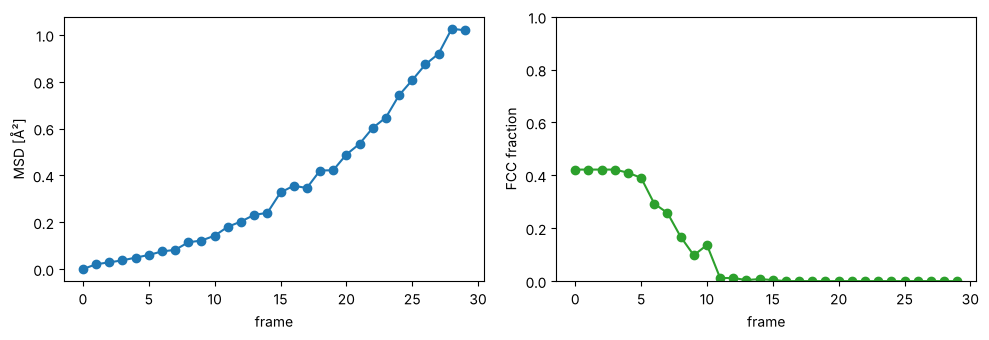

In [6]:
msd, fcc = [], []
for frame in range(pipeline.source.num_frames):
    d = pipeline.compute(frame)
    msd.append(np.mean(d.particles['Displacement Magnitude'] ** 2))
    fcc.append(d.attributes['CommonNeighborAnalysis.counts.FCC'] / d.particles.count)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(msd, 'o-'); ax[0].set(xlabel='frame', ylabel='MSD [Å²]')
ax[1].plot(fcc, 'o-', color='tab:green'); ax[1].set(xlabel='frame', ylabel='FCC fraction', ylim=(0, 1))
plt.tight_layout(); plt.show()

> **Why is the FCC fraction not 1 even at frame 0?** Without periodic boundaries, surface atoms do not have enough neighbors and are classified as "Other".

## 5. Your own calculations: use the data as NumPy arrays

OVITO properties can be used directly as NumPy arrays. As an example, compare displacement with distance from the center.

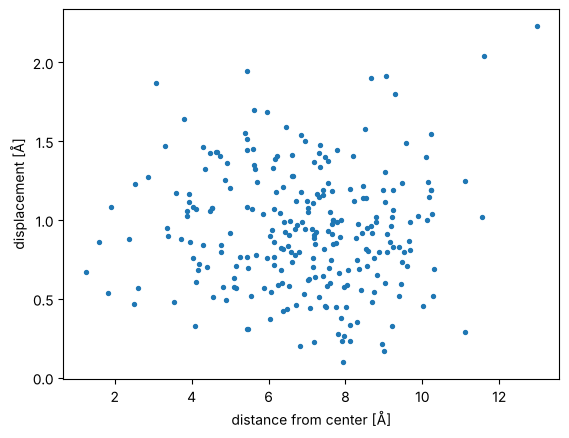

In [7]:
d = pipeline.compute(pipeline.source.num_frames - 1)
pos = np.asarray(d.particles.positions)
r = np.linalg.norm(pos - pos.mean(axis=0), axis=1)
plt.scatter(r, d.particles['Displacement Magnitude'], s=8)
plt.xlabel('distance from center [Å]'); plt.ylabel('displacement [Å]'); plt.show()

## 6. Render images

The surface gets in the way, so `SliceModifier` keeps only a thin layer in the middle, viewed from the top. Green is FCC, white is Other.

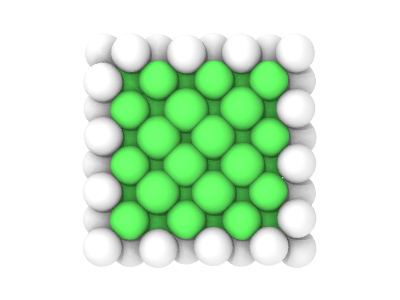

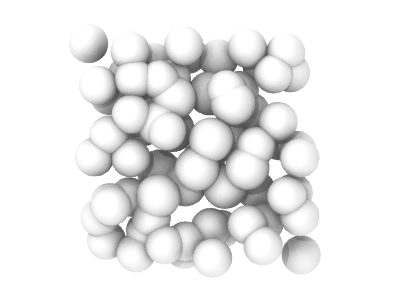

In [8]:
from ovito.modifiers import SliceModifier
from ovito.vis import Viewport, TachyonRenderer
from IPython.display import Image, display

zc = float(np.mean(pipeline.compute(0).particles.positions[:, 2]))
pipeline.modifiers.append(SliceModifier(normal=(0, 0, 1), distance=zc, slab_width=4.0))
pipeline.add_to_scene()

vp = Viewport(type=Viewport.Type.Top)
vp.zoom_all()
for frame in [0, pipeline.source.num_frames - 1]:
    fname = f'snapshot_{frame}.png'
    vp.render_image(filename=fname, size=(400, 300), frame=frame, renderer=TachyonRenderer())
    display(Image(fname))

## What to try next

- Replace `CommonNeighborAnalysisModifier` with `PolyhedralTemplateMatchingModifier`
- Compute the RDF with `CoordinationAnalysisModifier(cutoff=4.0)` (see `../python/analyze.py`)
- Change `XYZ` to your own simulation's xyz file and repeat the same steps